In [1]:
from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from astropy.time import Time
from astropy.coordinates import EarthLocation, AltAz, get_sun, SkyCoord
import numpy as np
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
import astropy.units as u
from astropy.coordinates import SkyCoord, EarthLocation
from astropy import time, coordinates as coord, units as u


/var/folders/h4/0wskt2390pb0wdv_2_zby2900000gn/T/ipykernel_4377/2833300739.py:1: DeprecationWarning: the ``nasa_exoplanet_archive`` module has been moved to astroquery.ipac.nexsci.nasa_exoplanet_archive, please update your imports.
  from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive


In [2]:
def predict_transits(planet_name, start_date, end_date, telescope_location, baseline_duration=None):
    from astropy.time import Time
    from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
    import astropy.units as u
    from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
    
    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    P = table["pl_orbper"][0].value  # Orbital period
    D = table["pl_trandur"][0].value / 24.0  # Transit duration in days
    
    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)
    
    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd
    
    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_transits = [T0 + (E * P) for E in range(E_start, E_end + 1)]
    
    # Observer location
    observer = EarthLocation.of_site(telescope_location)
    
    visible_transits = []

    for transit_mid in future_transits:
        if baseline_duration:
            total_duration = D + (2 * baseline_duration)
        else:
            total_duration = D
        
        transit_start = transit_mid - (total_duration / 2)
        transit_end = transit_mid + (total_duration / 2)
        
        time_start = Time(transit_start, format="jd")
        time_mid = Time(transit_mid, format="jd")
        time_end = Time(transit_end, format="jd")
        
        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)
        
        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)
        
        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt
        
        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz
        
        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg \
                and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 3 and end_airmass < 3:
                visible_transits.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))
    
    # Print results
    if visible_transits:
        print(f"\nUpcoming transits for {planet_name} at {telescope_location}:")
        for i, (start_transit_utc, mid_transit_utc, end_transit_utc, mid_airmass) in enumerate(visible_transits):
            print(f"Transit {i+1}: {start_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{mid_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{end_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Airmass: {mid_airmass:.3f}")
    else:
        print("No visible transits found in the given date range.")


In [3]:
def predict_transits(planet_name, start_date, end_date, telescope_location, baseline_duration=None, plot=False):
    from astropy.time import Time
    from astropy.coordinates import SkyCoord, EarthLocation, AltAz, get_sun
    import astropy.units as u
    from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
    import matplotlib.pyplot as plt
    import numpy as np

    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    P = table["pl_orbper"][0].value  # Orbital period
    D = table["pl_trandur"][0].value / 24.0  # Transit duration in days

    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)

    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd

    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_transits = [T0 + (E * P) for E in range(E_start, E_end + 1)]

    # Observer location
    observer = EarthLocation.of_site(telescope_location)

    visible_transits = []

    for transit_mid in future_transits:
        if baseline_duration:
            total_duration = D + (2 * baseline_duration)
        else:
            total_duration = D

        transit_start = transit_mid - (total_duration / 2)
        transit_end = transit_mid + (total_duration / 2)

        time_start = Time(transit_start, format="jd")
        time_mid = Time(transit_mid, format="jd")
        time_end = Time(transit_end, format="jd")

        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)

        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)

        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt

        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz

        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg \
                and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass < 3 and end_airmass < 3:
                visible_transits.append((time_start.datetime, time_mid.datetime, time_end.datetime, mid_airmass))

    # Print results
    if visible_transits:
        print(f"\nUpcoming transits for {planet_name} at {telescope_location}:")
        for i, (start_transit_utc, mid_transit_utc, end_transit_utc, mid_airmass) in enumerate(visible_transits):
            print(f"Transit {i+1}: {start_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{mid_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | "
                  f"{end_transit_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Airmass: {mid_airmass:.3f}")
    else:
        print("No visible transits found in the given date range.")

   
    # Plotting
    if plot and visible_transits:
        for i, (start_transit, mid_transit, end_transit, mid_airmass) in enumerate(visible_transits):
            plt.figure(figsize=(10, 6))  # Create a new figure for each transit

            print(type(start_transit))  # Debugging type
            
            # Convert datetime to astropy Time
            start_time = Time(start_transit)  
            end_time = Time(end_transit)  
            
            # Compute baseline start and end if applicable
            if baseline_duration:
                baseline_start_time = start_time - baseline_duration * u.day
                baseline_end_time = end_time + baseline_duration * u.day
            else:
                baseline_start_time = start_time
                baseline_end_time = end_time
            
            # Convert to Julian Date before using np.linspace
            start_jd = baseline_start_time.jd  # Extend to baseline start
            end_jd = baseline_end_time.jd  # Extend to baseline end
            
            times = np.linspace(start_jd, end_jd, 150)  # Increase points for smoothness
            
            airmasses = []
            for t in times:
                time = Time(t, format='jd')  # Convert back to Time object
                altaz = AltAz(obstime=time, location=observer)
                planet_altaz = planet.transform_to(altaz)
                airmasses.append(planet_altaz.secz.value)
            
            # Convert times for plotting
            datetime_array = Time(times, format='jd').datetime  # Use .datetime instead of .to_datetime()

            plt.plot(datetime_array, airmasses, 
                    label=f"Transit {i+1} | {mid_transit.strftime('%Y-%m-%d %H:%M:%S')} UTC")
            
            # Plot vertical lines for transit events
            plt.axvline(start_transit, color='r', linestyle='--', label='Start of Transit' if i == 0 else "")
            plt.axvline(mid_transit, color='g', linestyle='--', label='Mid Transit' if i == 0 else "")
            plt.axvline(end_transit, color='b', linestyle='--', label='End of Transit' if i == 0 else "")

            # Plot baseline start and end if applicable
            if baseline_duration:
                baseline_start = baseline_start_time.datetime
                baseline_end = baseline_end_time.datetime

                plt.axvline(baseline_start, color='c', linestyle='--', label='Baseline Start' if i == 0 else "")
                plt.axvline(baseline_end, color='m', linestyle='--', label='Baseline End' if i == 0 else "")

            plt.xlabel('Time (UTC)')
            plt.ylabel('Airmass')
            plt.legend()
            plt.show()  # Show each plot separately


UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]



Upcoming transits for KELT-9b at Canada-France-Hawaii Telescope:
Transit 1: 2025-09-04 06:51:15 UTC | 2025-09-04 09:48:44 UTC | 2025-09-04 12:46:12 UTC | Airmass: 1.166
Transit 2: 2025-09-07 05:56:53 UTC | 2025-09-07 08:54:22 UTC | 2025-09-07 11:51:50 UTC | Airmass: 1.101
<class 'datetime.datetime'>


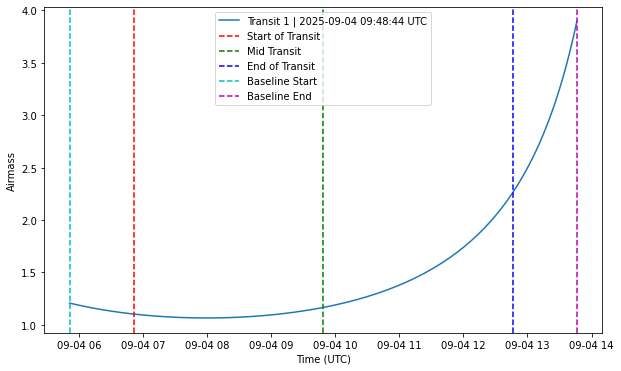

<class 'datetime.datetime'>


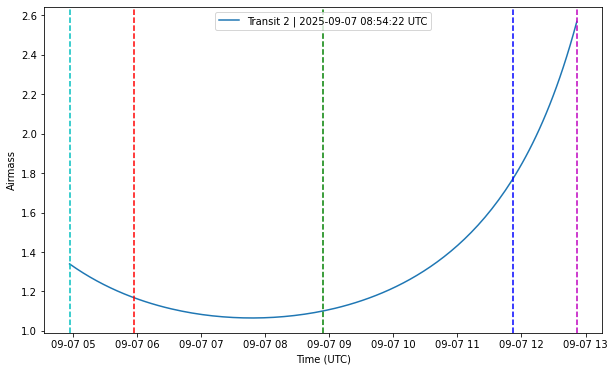

In [4]:
predict_transits("KELT-9b", start_date="2025-09-01", end_date="2025-09-15",  telescope_location='Canada-France-Hawaii Telescope',baseline_duration=1/24, plot=True)


In [5]:

def predict_emission(planet_name, start_date, end_date, telescope_location,phase,plot):
    # Query NASA Exoplanet Archive for the planet's data
    table = NasaExoplanetArchive.query_object(planet_name, table="pscomppars")
    
    T0 = table["pl_tranmid"][0].value  # Mid-transit time (BJD)
    P = table["pl_orbper"][0].value  # Orbital period
    D = table["pl_trandur"][0].value / 24.0  # Transit duration in days
    
    # Define the planet's sky coordinates
    planet = SkyCoord.from_name(planet_name)
    
    # phases = ((time_observations.jd - T0)/P)%1
    # phases = np.where(phases < 0.5, 1+phases, phases) # To have them as a monotic sequence
    # phases=(np.sort(phases))

    # Convert start and end dates to JD
    start_jd = Time(start_date).jd
    end_jd = Time(end_date).jd
    
    # Compute transit epochs within the given time range
    E_start = int((start_jd - T0) / P)
    E_end = int((end_jd - T0) / P)
    future_phases = [T0 + (E * P) + (phase * P) for E in range(E_start, E_end + 1)]
    # Observer location
    observer = EarthLocation.of_site(telescope_location)


    visible_phases = []

    for phase_mid in future_phases:
        phase_start = phase_mid - (D / 2)
        phase_end = phase_mid + (D / 2)
        
        time_start = Time(phase_start, format='jd')
        time_mid = Time(phase_mid, format='jd')
        time_end = Time(phase_end, format='jd')

        altaz_start = AltAz(obstime=time_start, location=observer)
        altaz_mid = AltAz(obstime=time_mid, location=observer)
        altaz_end = AltAz(obstime=time_end, location=observer)
        
        planet_altaz_start = planet.transform_to(altaz_start)
        planet_altaz_mid = planet.transform_to(altaz_mid)
        planet_altaz_end = planet.transform_to(altaz_end)
        
        sun_alt_start = get_sun(time_start).transform_to(altaz_start).alt
        sun_alt_mid = get_sun(time_mid).transform_to(altaz_mid).alt
        sun_alt_end = get_sun(time_end).transform_to(altaz_end).alt
    
        start_airmass = planet_altaz_start.secz
        mid_airmass = planet_altaz_mid.secz
        end_airmass = planet_altaz_end.secz

        if mid_airmass > 0 and planet_altaz_start.alt > 0 * u.deg and planet_altaz_mid.alt > 0 * u.deg and planet_altaz_end.alt > 0 * u.deg and sun_alt_start < -12 * u.deg and sun_alt_end < -12 * u.deg:
            if mid_airmass < 2 and start_airmass< 2.5 and end_airmass<2.5:
                visible_phases.append((time_start.datetime, time_mid.datetime, time_end.datetime,mid_airmass))
    
        # visible_transits.append((time_mid.datetime, mid_airmass))
    
    # Print results
    if visible_phases:
        print(f"\nUpcoming fully visible phase {phase} for {planet_name} at {telescope_location}:")
        for i, (start_phase_utc, mid_phase_utc, end_phase_utc, mid_airmass) in enumerate(visible_phases):
            print(f"Phase {i+1}: {start_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC |{mid_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | {end_phase_utc.strftime('%Y-%m-%d %H:%M:%S')} UTC | Mid Airmass: {mid_airmass:.3f}")
    else:
        print("No fully visible phases found in the given date range.")

    # Plotting
    if plot and visible_phases:
        for i, (start_phase, mid_phase, end_phase, mid_airmass) in enumerate(visible_phases):
            plt.figure(figsize=(10, 6))  # Create a new figure for each transit

            
            # Convert datetime to astropy Time
            start_time = Time(start_phase)  
            end_time = Time(end_phase)  
            
            # Compute baseline start and end if applicable
            
            baseline_start_time = start_time
            baseline_end_time = end_time
            
            # Convert to Julian Date before using np.linspace
            start_jd = baseline_start_time.jd  # Extend to baseline start
            end_jd = baseline_end_time.jd  # Extend to baseline end
            
            times = np.linspace(start_jd, end_jd, 150)  # Increase points for smoothness
            
            airmasses = []
            for t in times:
                time = Time(t, format='jd')  # Convert back to Time object
                altaz = AltAz(obstime=time, location=observer)
                planet_altaz = planet.transform_to(altaz)
                airmasses.append(planet_altaz.secz.value)
            
            # Convert times for plotting
            datetime_array = Time(times, format='jd').datetime  # Use .datetime instead of .to_datetime()

            plt.plot(datetime_array, airmasses, 
                    label=f"Phase {i+1} | {mid_phase.strftime('%Y-%m-%d %H:%M:%S')} UTC")
            
            # Plot vertical lines for transit events
            plt.axvline(start_phase, color='r', linestyle='--', label='Start of Transit' if i == 0 else "")
            plt.axvline(mid_phase, color='g', linestyle='--', label='Mid Transit' if i == 0 else "")
            plt.axvline(end_phase, color='b', linestyle='--', label='End of Transit' if i == 0 else "")

            # Plot baseline start and end if applicable
        
            plt.xlabel('Time (UTC)')
            plt.ylabel('Airmass')
            plt.legend()
            plt.show()  # Show each plot separately


Upcoming fully visible phase 0.88 for KELT-9b at Canada-France-Hawaii Telescope:
Phase 1: 2025-08-14 09:55:52 UTC |2025-08-14 11:53:20 UTC | 2025-08-14 13:50:49 UTC | Mid Airmass: 1.272


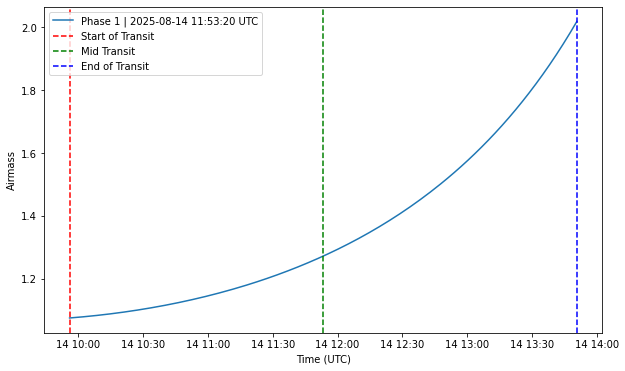

In [6]:
predict_emission("KELT-9b", start_date="2025-08-03", end_date="2025-08-14",  telescope_location='Canada-France-Hawaii Telescope', phase=0.88,plot=True )
